# Experiment 7: training episode size — results

Compare 2,048, 8,192 and 26,000 total training rows on one fixed large-table pool. The 8,192-row control is reused explicitly from experiment 6. Context and query size both increase; update budgets, not compute or row exposures, are matched.

Does a longer training episode improve credit transfer within the same large-table corpus? Both context and query rows increase; updates are matched, compute is not.


## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, size_studies as ss
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('experiment7/02_results')
report = cp.NotebookReport('Experiment 7: training episode size — results', sink=sink)
print(source_description())
arms = ss.load_arms(7)
report.add('0. Evidence and scope', source_description() + '\n' + 'Compare 2,048, 8,192 and 26,000 total training rows on one fixed large-table pool. The 8,192-row control is reused explicitly from experiment 6. Context and query size both increase; update budgets, not compute or row exposures, are matched.')
from src.visualize import prediction_diagnostics as pred


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


## 1. Coverage and the fixed evaluation population

In [2]:
report.table('Planned and recorded evidence', ss.coverage(arms))
report.table('Prepared corpus and exposure inventory', ss.corpus_inventory(arms))
report.add('1. Coverage and the fixed evaluation population', 'Missing records are unavailable evidence. PENDING is not a live scheduler state. The four original dataset partitions and five row-level evaluation folds remain fixed. Shared controls count once.')

,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,"2,048 rows",experiment7,cpt_episode_rows2048_v1,8,8,0,0,48,1155
1,"8,192 rows",experiment6,cpt_corpus_v1,8,8,0,0,48,1155
2,"26,000 rows",experiment7,cpt_episode_rows26000_v1,8,8,0,0,48,1155


,arm,partition,id,available_rows,episode_rows,query_rows,visit_share,held_out_tables
0,"2,048 rows",0,0001.gmsc,150000,2048,819,0.111111,4
1,"2,048 rows",0,0002.taiwan_creditcard,30000,2048,819,0.111111,4
2,"2,048 rows",0,0003.vehicle_loan,233154,2048,819,0.111111,4
3,"2,048 rows",0,0006.hackerearth,532428,2048,819,0.111111,4
4,"2,048 rows",0,0007.cobranded,80000,2048,819,0.111111,4
...,...,...,...,...,...,...,...,...
94,"26,000 rows",3,PropPD1,100000,26000,10400,0.111111,4
95,"26,000 rows",3,PropPD2,105471,26000,10400,0.111111,4
96,"26,000 rows",3,0014.algorithmwatch,158700,26000,10400,0.111111,4
97,"26,000 rows",3,0015.credit_risk_dataset,32581,26000,10400,0.111111,4


## 2. Paired AUC effects and study contrasts

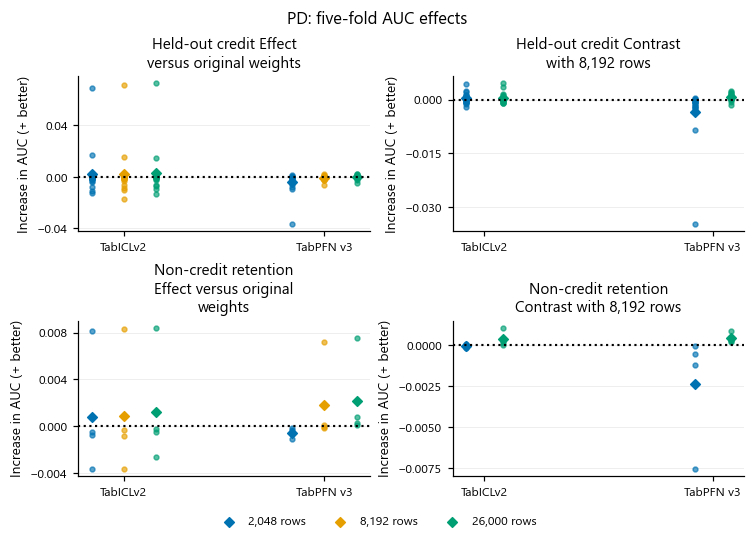

Points are table-level paired effects and diamonds are equal-table means. Five finite outer folds are required for both CPT and its original-weight control, and every displayed arm must be present for the same table. Non-credit effects first average the four matched training partitions. Right panels subtract the 8,192 rows effect within table. Positive values indicate improvement; points are not independent across related data sources. The 8,192-row large-table checkpoint is shared across experiments 6 and 7, not an independent replication.

In [3]:
cp.show(sink, ss.plot_benchmark(arms))
report.add('2. Paired AUC effects and study contrasts', 'Report all prescribed arms. Each table is paired across arms and its original-weight control, requiring complete five-fold evaluation. Partitions and CV folds are not independent replications.')

## 3. Probability quality

Saved raw test predictions additionally measure systematic over/underprediction and paired prediction changes. These diagnostics describe observed errors; they do not identify theoretical bias or context variance.


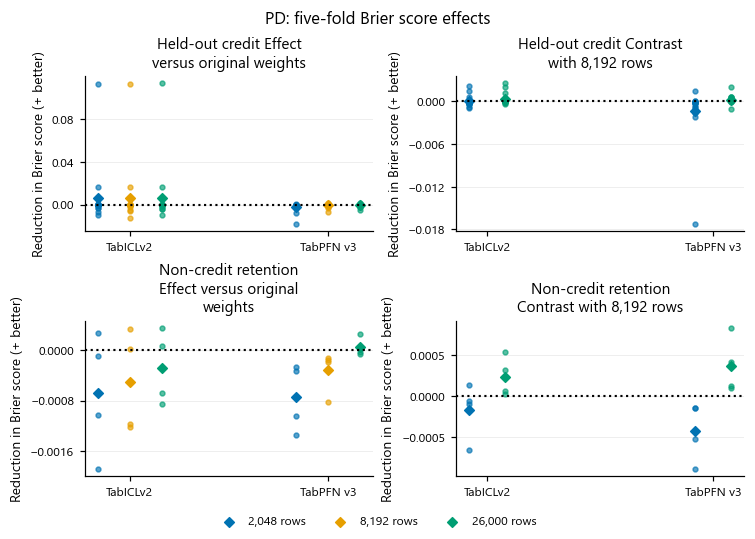

Points are table-level paired effects and diamonds are equal-table means. Five finite outer folds are required for both CPT and its original-weight control, and every displayed arm must be present for the same table. Non-credit effects first average the four matched training partitions. Right panels subtract the 8,192 rows effect within table. Positive values indicate improvement; points are not independent across related data sources. The 8,192-row large-table checkpoint is shared across experiments 6 and 7, not an independent replication.

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,German Credit,1,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Taiwan Credit Card,1,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Vehicle Loan,1,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Credit Risk,2,"2,048 rows",verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,Hackerearth,2,"2,048 rows",verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,"2,048 rows",730176,0.138105,0.135123,0.134643,-0.002982,-0.003462,-0.000480,0.080536,0.080862,-0.000326,-0.000480,0.020933,0.009787
1,TabICLv2,HMEQ,0,"2,048 rows",5960,0.199497,0.190717,0.188948,-0.008779,-0.010548,-0.001769,0.017686,0.020941,-0.003255,-0.001769,0.038533,0.013901
2,TabICLv2,MicroFinance,0,"2,048 rows",158700,0.378091,0.364956,0.365715,-0.013134,-0.012376,0.000759,0.218164,0.218252,-0.000088,0.000759,0.031700,0.024029
3,TabICLv2,Thomas,0,"2,048 rows",1225,0.263673,0.247090,0.242784,-0.016584,-0.020889,-0.004306,0.183083,0.183565,-0.000482,-0.004306,0.020418,0.014704
4,TabICLv2,GMSC,1,"2,048 rows",150000,0.066840,0.057865,0.057802,-0.008975,-0.009038,-0.000063,0.049076,0.049143,-0.000068,-0.000063,0.006463,0.003157
5,TabICLv2,German Credit,1,"2,048 rows",999,0.300300,0.292743,0.290471,-0.007557,-0.009829,-0.002273,0.162400,0.161862,0.000538,-0.002273,0.027553,0.019484
6,TabICLv2,Taiwan Credit Card,1,"2,048 rows",30000,0.221200,0.206801,0.206299,-0.014399,-0.014901,-0.000501,0.132926,0.133337,-0.000411,-0.000501,0.018467,0.012866
7,TabICLv2,Vehicle Loan,1,"2,048 rows",233154,0.217071,0.387294,0.200399,0.170223,-0.016672,0.153551,0.274762,0.162564,0.112198,-0.186896,0.342692,0.211712
8,TabICLv2,Credit Risk,2,"2,048 rows",32581,0.218164,0.207034,0.209013,-0.011130,-0.009151,0.001979,0.049365,0.056152,-0.006787,0.001979,0.066207,0.033389
9,TabICLv2,Hackerearth,2,"2,048 rows",532428,0.236327,0.231125,0.216108,-0.005201,-0.020219,-0.015017,0.058127,0.067926,-0.009799,-0.015017,0.090890,0.042310


,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,German Credit,1,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Taiwan Credit Card,1,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Vehicle Loan,1,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Credit Risk,2,"8,192 rows",verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,Hackerearth,2,"8,192 rows",verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,"8,192 rows",730176,0.138105,0.135123,0.133006,-0.002982,-0.005099,-0.002117,0.080536,0.080545,-0.000010,-0.002117,0.019760,0.009311
1,TabICLv2,HMEQ,0,"8,192 rows",5960,0.199497,0.190717,0.193290,-0.008779,-0.006207,0.002573,0.017686,0.022467,-0.004781,0.002573,0.048580,0.018183
2,TabICLv2,MicroFinance,0,"8,192 rows",158700,0.378091,0.364956,0.368367,-0.013134,-0.009724,0.003411,0.218164,0.218378,-0.000214,0.003411,0.030211,0.022704
3,TabICLv2,Thomas,0,"8,192 rows",1225,0.263673,0.247090,0.242592,-0.016584,-0.021081,-0.004498,0.183083,0.183812,-0.000729,-0.004498,0.022282,0.014948
4,TabICLv2,GMSC,1,"8,192 rows",150000,0.066840,0.057865,0.057640,-0.008975,-0.009200,-0.000225,0.049076,0.049151,-0.000075,-0.000225,0.006955,0.003296
5,TabICLv2,German Credit,1,"8,192 rows",999,0.300300,0.292743,0.289789,-0.007557,-0.010512,-0.002955,0.162400,0.162447,-0.000047,-0.002955,0.028202,0.019911
6,TabICLv2,Taiwan Credit Card,1,"8,192 rows",30000,0.221200,0.206801,0.206487,-0.014399,-0.014713,-0.000314,0.132926,0.133250,-0.000324,-0.000314,0.016720,0.011699
7,TabICLv2,Vehicle Loan,1,"8,192 rows",233154,0.217071,0.387294,0.195776,0.170223,-0.021295,0.148929,0.274762,0.161803,0.112959,-0.191518,0.348573,0.215671
8,TabICLv2,Credit Risk,2,"8,192 rows",32581,0.218164,0.207034,0.207001,-0.011130,-0.011163,-0.000034,0.049365,0.055204,-0.005840,-0.000034,0.059807,0.028837
9,TabICLv2,Hackerearth,2,"8,192 rows",532428,0.236327,0.231125,0.219707,-0.005201,-0.016619,-0.011418,0.058127,0.070155,-0.012027,-0.011418,0.102699,0.049356


,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,German Credit,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,Taiwan Credit Card,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,Vehicle Loan,1,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
8,TabICLv2,Credit Risk,2,"26,000 rows",verified,"Five folds; matched row identities, targets an..."
9,TabICLv2,Hackerearth,2,"26,000 rows",verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,"26,000 rows",730176,0.138105,0.135123,0.133214,-0.002982,-0.004891,-0.001909,0.080536,0.080609,-0.000073,-0.001909,0.019924,0.009614
1,TabICLv2,HMEQ,0,"26,000 rows",5960,0.199497,0.190717,0.194465,-0.008779,-0.005031,0.003748,0.017686,0.021260,-0.003574,0.003748,0.044608,0.015359
2,TabICLv2,MicroFinance,0,"26,000 rows",158700,0.378091,0.364956,0.363308,-0.013134,-0.014782,-0.001648,0.218164,0.218585,-0.000421,-0.001648,0.030119,0.022415
3,TabICLv2,Thomas,0,"26,000 rows",1225,0.263673,0.247090,0.243615,-0.016584,-0.020059,-0.003475,0.183083,0.183625,-0.000542,-0.003475,0.018190,0.012581
4,TabICLv2,GMSC,1,"26,000 rows",150000,0.066840,0.057865,0.056682,-0.008975,-0.010158,-0.001183,0.049076,0.049140,-0.000065,-0.001183,0.006866,0.003306
5,TabICLv2,German Credit,1,"26,000 rows",999,0.300300,0.292743,0.290877,-0.007557,-0.009423,-0.001867,0.162400,0.162818,-0.000418,-0.001867,0.028216,0.019580
6,TabICLv2,Taiwan Credit Card,1,"26,000 rows",30000,0.221200,0.206801,0.205003,-0.014399,-0.016197,-0.001797,0.132926,0.133203,-0.000277,-0.001797,0.014475,0.010397
7,TabICLv2,Vehicle Loan,1,"26,000 rows",233154,0.217071,0.387294,0.194414,0.170223,-0.022657,0.147566,0.274762,0.161721,0.113041,-0.192880,0.349053,0.216262
8,TabICLv2,Credit Risk,2,"26,000 rows",32581,0.218164,0.207034,0.210042,-0.011130,-0.008122,0.003008,0.049365,0.053114,-0.003750,0.003008,0.047709,0.022788
9,TabICLv2,Hackerearth,2,"26,000 rows",532428,0.236327,0.231125,0.223301,-0.005201,-0.013026,-0.007825,0.058127,0.067629,-0.009501,-0.007825,0.089664,0.042675


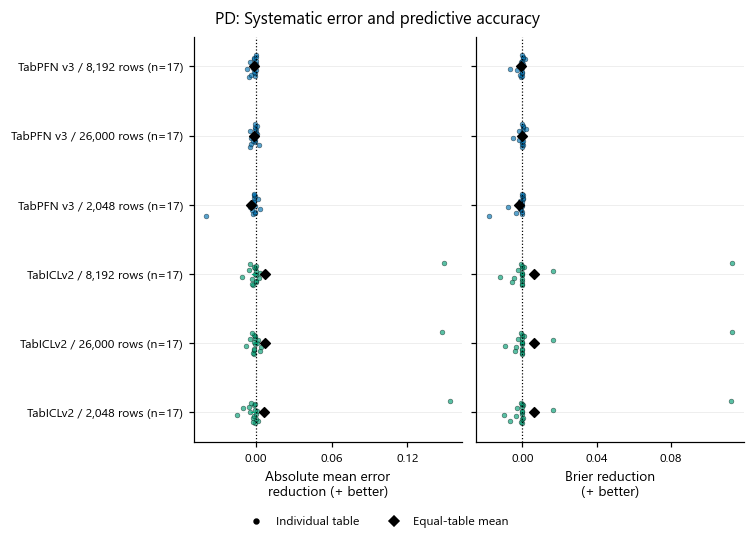

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

In [4]:
cp.show(sink, ss.plot_benchmark(arms, 'brier_score'))
prediction_tables, coverage_tables = [], []
for arm, run in arms.items():
    values, coverage = pred.analyze(run, arm=arm)
    prediction_tables.append(values)
    coverage_tables.append(coverage)
    report.table(arm+' saved prediction coverage', coverage)
    report.table(arm+' paired per-table prediction diagnostics', values)
cp.show(sink, pred.plot_arms(prediction_tables, coverage_tables, 'pd'), track='pd')
report.add('3. Probability quality', 'Positive Brier effects mean a reduction in error. These are secondary outcomes at natural test prevalence; do not select an arm with them.' + '\n' + pred.NOTE)


## 4. Interpretation

In [5]:
report.table('Completed and unavailable comparisons', ss.coverage(arms))
report.add('4. Interpretation', 'Compare 2,048, 8,192 and 26,000 total training rows on one fixed large-table pool. The 8,192-row control is reused explicitly from experiment 6. Context and query size both increase; update budgets, not compute or row exposures, are matched. Differences are descriptive for this credit corpus, horizon and two base architectures. These studies do not estimate a corpus-by-episode interaction or an effect of dataset size independent of population identity.')

,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,"2,048 rows",experiment7,cpt_episode_rows2048_v1,8,8,0,0,48,1155
1,"8,192 rows",experiment6,cpt_corpus_v1,8,8,0,0,48,1155
2,"26,000 rows",experiment7,cpt_episode_rows26000_v1,8,8,0,0,48,1155


## Complete text summary

In [6]:
print(report.summary(sink))

Experiment 7: training episode size — results

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Compare 2,048, 8,192 and 26,000 total training rows on one fixed large-table pool. The 8,192-row control is reused explicitly from experiment 6. Context and query size both increase; update budgets, not compute or row exposures, are matched.

1. Coverage and the fixed evaluation population
Missing records are unavailable evidence. PENDING is not a live scheduler state. The four original dataset partitions and five row-level evaluation folds remain fixed. Shared controls count once.

Table: Planned and recorded evidence
CSV (first column: row index)
row,arm,source_experiment,source_run,planned,completed,other_outcomes,pending,trajectory_records,benchmark_fold_records
0,"2,048 rows",experiment7,cpt_episode_rows2048_v1,8,8,0,0,48,1155
1,"8,192 rows",experiment6,cp